Dataset loaded successfully!
Dataset Shape: (7043, 21)
Missing values: 0


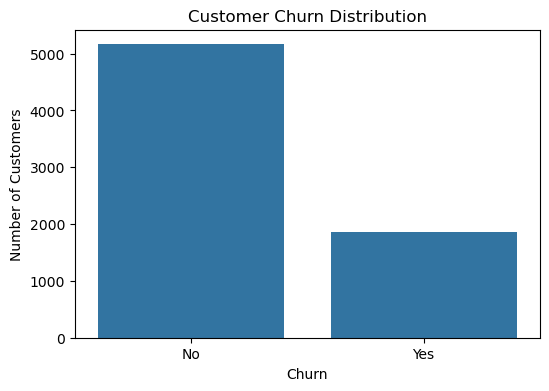

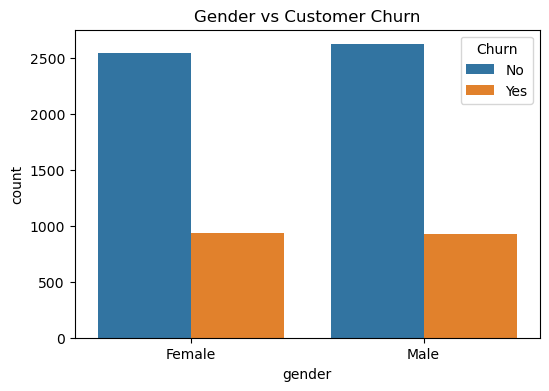

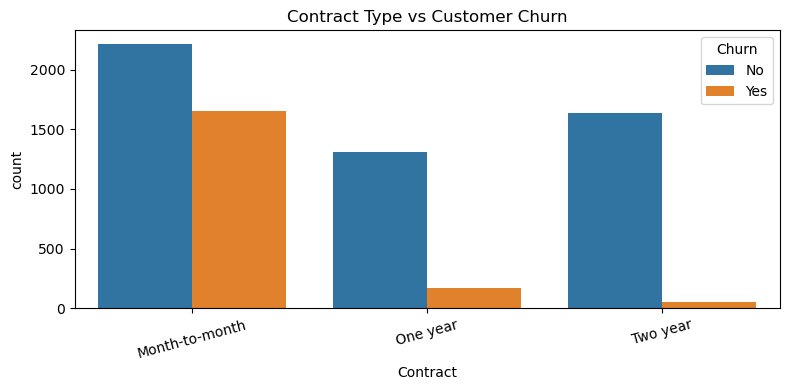

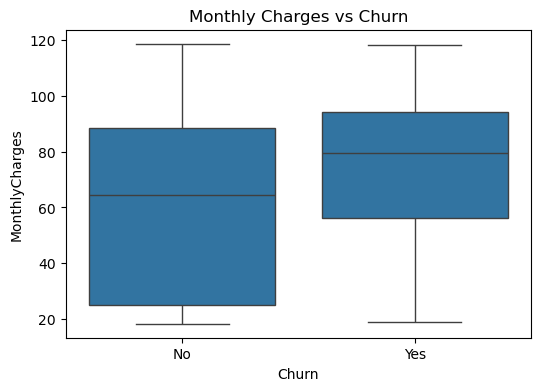

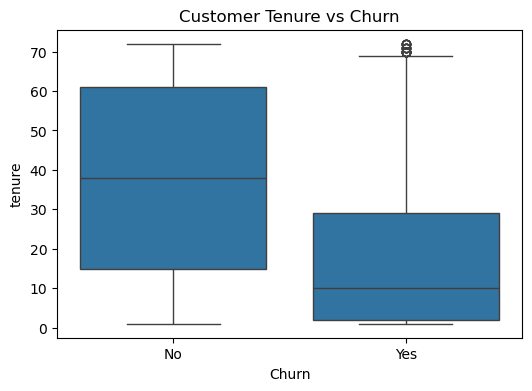

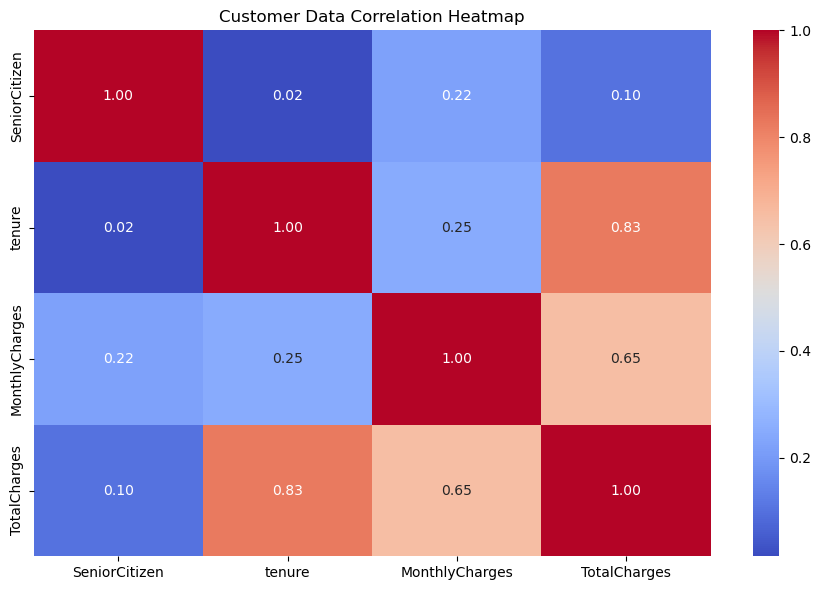

Feature columns saved successfully!
Total Features: 30

Saved Feature Columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']

Top 10 Important Features:
TotalCharges                      0.191435
tenure                            0.171020
MonthlyCharges                    0.168400
Inter

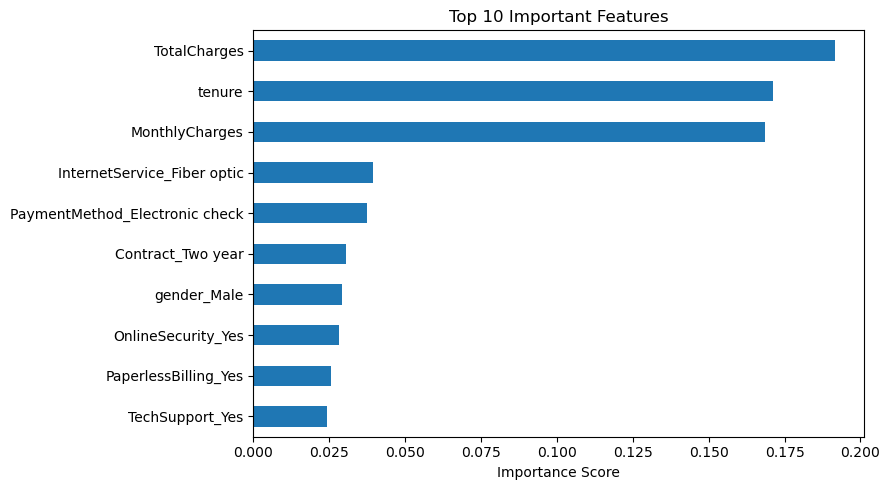


CUSTOMER CHURN PROJECT STATUS
Dataset loaded: YES
Data cleaning: YES
EDA completed: YES
Feature encoding: YES
Feature columns saved: YES
Feature columns file exists: True

Project feature preparation completed!


In [3]:
# =====================================================
# CUSTOMER CHURN PREDICTION - FEATURE COLUMNS & EDA
# =====================================================

# 1. Import libraries
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 2. Load dataset
df = pd.read_csv(r"C:\Users\swapn\Downloads\WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

# 3. Data cleaning
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'], errors='coerce'
)

df = df.dropna()

print("Missing values:", df.isnull().sum().sum())

# =====================================================
# 4. EXPLORATORY DATA ANALYSIS (EDA)
# =====================================================

# Graph 1: Customer Churn Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn')
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

# Graph 2: Gender vs Churn
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='gender', hue='Churn')
plt.title("Gender vs Customer Churn")
plt.show()

# Graph 3: Contract vs Churn
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='Contract', hue='Churn')
plt.title("Contract Type vs Customer Churn")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Graph 4: Monthly Charges vs Churn
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title("Monthly Charges vs Churn")
plt.show()

# Graph 5: Tenure vs Churn
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='Churn', y='tenure')
plt.title("Customer Tenure vs Churn")
plt.show()

# Graph 6: Correlation Heatmap
numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr()

plt.figure(figsize=(9, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title("Customer Data Correlation Heatmap")
plt.tight_layout()
plt.show()

# =====================================================
# 5. FEATURE ENGINEERING
# =====================================================

# Separate features and target
X = df.drop(columns=['customerID', 'Churn'])

y = df['Churn'].map({
    'Yes': 1,
    'No': 0
})

# Convert categorical columns into numerical values
X = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

# Save feature column names
feature_columns = X.columns.tolist()

joblib.dump(
    feature_columns,
    "feature_columns.pkl"
)

print("Feature columns saved successfully!")

print("Total Features:", len(feature_columns))

# =====================================================
# 6. VERIFY FEATURE COLUMNS
# =====================================================

loaded_features = joblib.load("feature_columns.pkl")

print("\nSaved Feature Columns:")
print(loaded_features)

# =====================================================
# 7. FEATURE IMPORTANCE GRAPH
# =====================================================

# Load trained model if already available
if os.path.exists("churn_model.pkl"):

    model = joblib.load("churn_model.pkl")

    if len(model.feature_importances_) == len(feature_columns):

        importance = pd.Series(
            model.feature_importances_,
            index=feature_columns
        ).sort_values(ascending=False)

        print("\nTop 10 Important Features:")
        print(importance.head(10))

        plt.figure(figsize=(9, 5))

        importance.head(10).sort_values().plot(
            kind='barh'
        )

        plt.title("Top 10 Important Features")
        plt.xlabel("Importance Score")
        plt.tight_layout()
        plt.show()

    else:
        print("Model features do not match. Retrain the model.")

else:
    print("Train and save churn_model.pkl first.")

# =====================================================
# 8. FINAL PROJECT STATUS
# =====================================================

print("\n================================")
print("CUSTOMER CHURN PROJECT STATUS")
print("================================")

print("Dataset loaded: YES")
print("Data cleaning: YES")
print("EDA completed: YES")
print("Feature encoding: YES")
print("Feature columns saved: YES")
print("Feature columns file exists:",
      os.path.exists("feature_columns.pkl"))

print("\nProject feature preparation completed!")